In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
accuracy_score, precision_score, recall_score,
f1_score,confusion_matrix, classification_report
)
print("Libraries import successfully")

Libraries import successfully


In [ ]:
#Loading the Dataset
df = pd.read_csv("/content/fire_smoke_detection_logistic_regression_dataset.csv")

print("Dataset loaded successfully")
print(df.head())

Dataset loaded successfully
   Temperature_C  Humidity_pct  Smoke_PPM  CO_PPM  Flame_Intensity  \
0          28.99         42.13      31.36    3.86           0.0176   
1          57.38         50.30     158.65   67.06           0.5358   
2          68.90         19.22     245.92  118.78           0.8334   
3          25.46         37.37      50.62    0.20           0.0511   
4          20.27         71.69       5.43    4.83           0.1009   

   Air_Quality_Index  Oxygen_pct  Wind_Speed_m_s  Sensor_Distance_m  \
0              79.88       20.11            2.16               3.16   
1             230.57       19.09            8.74               2.78   
2             268.61       18.75            2.37               8.50   
3              71.34       20.76            3.65               9.75   
4              27.81       20.98            8.13               6.44   

   Fire_Smoke  
0           0  
1           1  
2           1  
3           0  
4           0  


In [ ]:
#Understanding the Dataset

#Inspect the dataset
print("First five rows:")
print(df.head())

print("Last five rows:")
print(df.tail())

print("\nDataset shape:")
print(df.shape)

print("\nDataset names:")
print(df.columns)

print("\nDataset info:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

First five rows:
   Temperature_C  Humidity_pct  Smoke_PPM  CO_PPM  Flame_Intensity  \
0          28.99         42.13      31.36    3.86           0.0176   
1          57.38         50.30     158.65   67.06           0.5358   
2          68.90         19.22     245.92  118.78           0.8334   
3          25.46         37.37      50.62    0.20           0.0511   
4          20.27         71.69       5.43    4.83           0.1009   

   Air_Quality_Index  Oxygen_pct  Wind_Speed_m_s  Sensor_Distance_m  \
0              79.88       20.11            2.16               3.16   
1             230.57       19.09            8.74               2.78   
2             268.61       18.75            2.37               8.50   
3              71.34       20.76            3.65               9.75   
4              27.81       20.98            8.13               6.44   

   Fire_Smoke  
0           0  
1           1  
2           1  
3           0  
4           0  
Last five rows:
       Temperature_C  H

In [ ]:
# Check Data Quality

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print(df['Fire_Smoke'].describe())

Missing values:
Temperature_C        0
Humidity_pct         0
Smoke_PPM            0
CO_PPM               0
Flame_Intensity      0
Air_Quality_Index    0
Oxygen_pct           0
Wind_Speed_m_s       0
Sensor_Distance_m    0
Fire_Smoke           0
dtype: int64

Duplicate Rows:
0
count    20000.000000
mean         0.277550
std          0.447801
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max          1.000000
Name: Fire_Smoke, dtype: float64


In [ ]:
df = df.drop_duplicates()

print("Duplicate rows:", df.duplicated().sum())
print("Final shape:", df.shape)

Duplicate rows: 0
Final shape: (20000, 10)


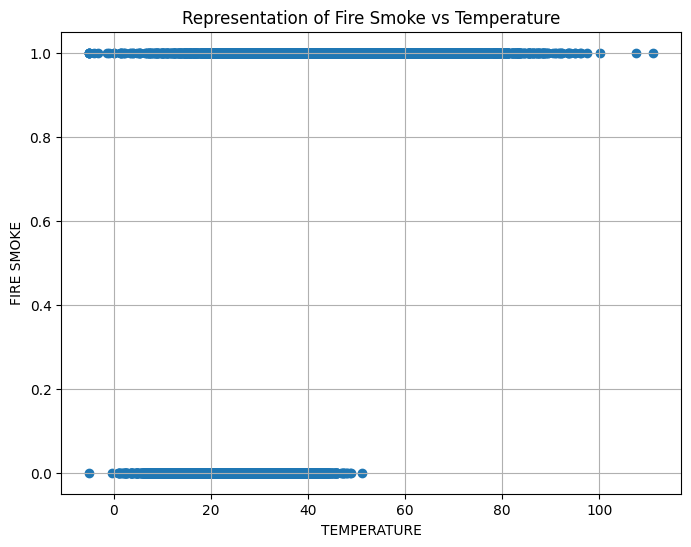

In [ ]:
#Graph 1 — Age Vs Heart Disease

plt.figure(figsize=(8, 6))

plt.scatter(df['Temperature_C'], df['Fire_Smoke'])

plt.xlabel('TEMPERATURE')
plt.ylabel('FIRE SMOKE')
plt.title('Representation of Fire Smoke vs Temperature')
plt.grid(True)

plt.show()

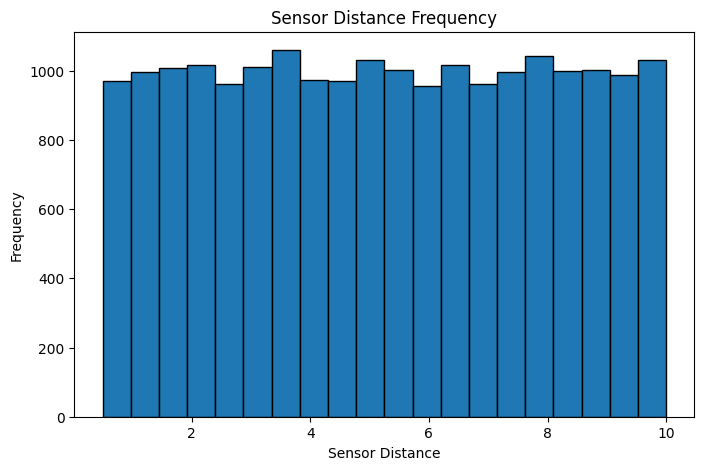

In [ ]:
# #Graph 2 — Sensor Distance FREQUENCY REPRESENTATION

plt.figure(figsize=(8, 5))

plt.hist(df['Sensor_Distance_m'], bins=20, edgecolor='black')

plt.title("Sensor Distance Frequency")
plt.xlabel("Sensor Distance")
plt.ylabel("Frequency")
plt.show()

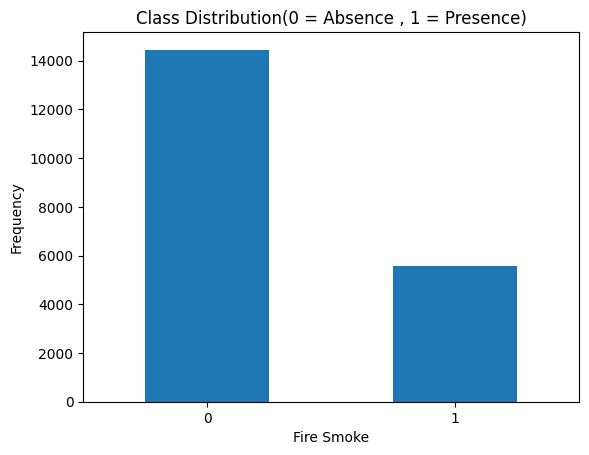

In [ ]:
#Fire Smoke REPESENTATION
df["Fire_Smoke"].value_counts().sort_index().plot(
    kind="bar",rot=0,title="Class Distribution(0 = Absence , 1 = Presence)"
)
plt.xlabel("Fire Smoke")
plt.ylabel("Frequency")
plt.show()

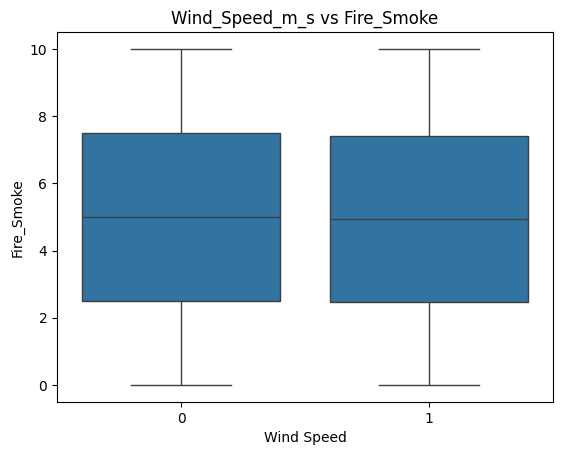

In [ ]:
#Fire Smoke vs Wind_Speed_m_s
sns.boxplot(data=df, x='Fire_Smoke', y='Wind_Speed_m_s')

plt.title("Wind_Speed_m_s vs Fire_Smoke")
plt.xlabel("Wind Speed")
plt.ylabel("Fire_Smoke")
plt.show()

In [ ]:
#Separate Features and Target
X = df[["Temperature_C","Humidity_pct","Air_Quality_Index","Oxygen_pct","Wind_Speed_m_s","Sensor_Distance_m"]]
Y = df["Fire_Smoke"]

print("Features(X): ")
print(X.head())
print("Target(y): ")
print(Y.head())

Features(X): 
   Temperature_C  Humidity_pct  Air_Quality_Index  Oxygen_pct  Wind_Speed_m_s  \
0          28.99         42.13              79.88       20.11            2.16   
1          57.38         50.30             230.57       19.09            8.74   
2          68.90         19.22             268.61       18.75            2.37   
3          25.46         37.37              71.34       20.76            3.65   
4          20.27         71.69              27.81       20.98            8.13   

   Sensor_Distance_m  
0               3.16  
1               2.78  
2               8.50  
3               9.75  
4               6.44  
Target(y): 
0    0
1    1
2    1
3    0
4    0
Name: Fire_Smoke, dtype: int64


In [ ]:
#Train-Test Split

X_train,X_test,Y_train,Y_test=train_test_split(
    X,Y,
    test_size= 0.25,
    random_state=42,
    stratify=Y
)

In [ ]:
#Feature scaling and Model Creation

model= Pipeline([
    ("scaler",StandardScaler()),
    ("classifier",LogisticRegression())
])

In [ ]:
#Train the Model
model.fit(X_train,Y_train)
print("Model Training Completed ")

Model Training Completed 


In [ ]:
#Predict the test Data
Y_pred=model.predict(X_test)
comparison=pd.DataFrame({
    "Actual_Result":Y_test.values,
    "Predicted_Result":Y_pred
})
print(comparison)

      Actual_Result  Predicted_Result
0                 0                 0
1                 0                 0
2                 1                 1
3                 0                 0
4                 0                 0
...             ...               ...
4995              0                 0
4996              0                 0
4997              0                 0
4998              0                 0
4999              0                 0

[5000 rows x 2 columns]


In [ ]:
#Confusion Matrix
cm=confusion_matrix(Y_test,Y_pred,labels=[0,1])
print("Rows= Actual, Columns= Predicted ")
print(cm)

Rows= Actual, Columns= Predicted 
[[3605    7]
 [  54 1334]]


In [ ]:
#Calculate Evaluation Matrics

accuracy=accuracy_score(Y_test,Y_pred)
precision=precision_score(Y_test,Y_pred,zero_division=0)
recall=recall_score(Y_test,Y_pred,zero_division=0)
f1=f1_score(Y_test,Y_pred,zero_division=0)

print("Accuracy: ",round(accuracy,3))
print("Precision: ",round(precision,3))
print("Recall: ",round(recall,3))
print("F1 Score: ",round(f1,3))

print("\n Detailed Classification Report: ")
print(classification_report(Y_test,Y_pred,
                            labels=[0,1],
                            target_names=["No Fire","Fire"],
                            zero_division=0))

Accuracy:  0.988
Precision:  0.995
Recall:  0.961
F1 Score:  0.978

 Detailed Classification Report: 
              precision    recall  f1-score   support

     No Fire       0.99      1.00      0.99      3612
        Fire       0.99      0.96      0.98      1388

    accuracy                           0.99      5000
   macro avg       0.99      0.98      0.98      5000
weighted avg       0.99      0.99      0.99      5000



### Visualizing the Confusion Matrix
Let's plot a heatmap of the confusion matrix to see the perfect classification.

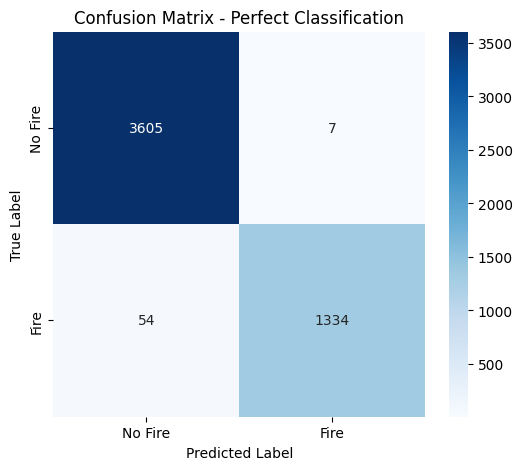

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Fire', 'Fire'],
            yticklabels=['No Fire', 'Fire'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Perfect Classification')
plt.show()

In [ ]:
# Understand Prediction Probability


probabilities = model.predict_proba(X_test)
print("Columns are ordered as classes : ",model.classes_)
print(probabilities)

Columns are ordered as classes :  [0 1]
[[9.99899493e-01 1.00507290e-04]
 [9.99728734e-01 2.71266188e-04]
 [4.93372482e-05 9.99950663e-01]
 ...
 [9.99942380e-01 5.76197241e-05]
 [9.99980293e-01 1.97069598e-05]
 [9.99833407e-01 1.66592544e-04]]


In [ ]:
# Predict for a New Sensor Reading
#

new_reading = pd.DataFrame({
    'Temperature_C': [45.0],            # Elevated Temperature
    'Humidity_pct': [25.0],             # Dry air
    'Air_Quality_Index': [180.0],       # Poor air quality
    'Oxygen_pct': [19.5],               # Slightly reduced oxygen
    'Wind_Speed_m_s': [5.5],            # Moderate wind
    'Sensor_Distance_m': [3.0]          # Close to sensor
})

predicted_class=model.predict(new_reading)[0]
Predicted_Probability=model.predict_proba(new_reading)[0]
if predicted_class == 0:
  print ("Predicted Result: No Fire")
else:
  print("Predicted Result: Fire")
print("Class Order:",model.classes_)
print("Predicted Probabilities:",Predicted_Probability)

Predicted Result: Fire
Class Order: [0 1]
Predicted Probabilities: [1.41475989e-04 9.99858524e-01]


In [ ]:
import joblib
import sklearn
#Save the trained model
joblib.dump(model, "Fire_Detection.pki")

#Check the installed scikit-learn version
print("Scikit-learn version:",sklearn.__version__)

print("Model saved successfully")

Scikit-learn version: 1.6.1
Model saved successfully


In [ ]:
from google.colab import files
files.download('Fire_Detection.pki')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>